# Практическая работа №6

## Классификация текстов — Вариант B

**Датасет:** IMDB Movie Reviews

**Цель:** реализовать очистку и нормализацию текстов, выполнить токенизацию, обучить классификатор с использованием TF-IDF и проанализировать ошибки модели.

**Целевая переменная:** label.

- 0 — отрицательный отзыв.
- 1 — положительный отзыв.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv(
    "../data/imdb_labelled.txt",
    sep="\t",
    header=None,
    names=["text", "label"]
)

display(df.head())

print("Размер датасета:", df.shape)

print("\nБаланс классов:")
print(df["label"].value_counts())

print("\nПропуски:")
print(df.isnull().sum())

,text,label
0,"A very, very, very slow-moving, aimless movie ...",0
1,Not sure who was more lost - the flat characte...,0
2,Attempting artiness with black & white and cle...,0
3,Very little music or anything to speak of.,0
4,The best scene in the movie was when Gerardo i...,1


Размер датасета: (748, 2)

Баланс классов:
label
1    386
0    362
Name: count, dtype: int64

Пропуски:
text     0
label    0
dtype: int64


### Первичный анализ данных

В работе используется датасет текстовых отзывов с двумя классами тональности.

Каждый отзыв имеет текст и метку: 0 — отрицательная тональность, 1 — положительная.

Перед обучением модели необходимо обработать текст и преобразовать его в числовое представление.

In [3]:
stop_words = set(ENGLISH_STOP_WORDS) - {
    "not", "no", "nor"
}

def clean_text(text):
    text = str(text).lower()

    # Удаляем цифры и пунктуацию
    text = re.sub(r"[^a-z\s]", " ", text)

    # Токенизация
    tokens = text.split()

    # Удаляем стоп-слова
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    return " ".join(tokens)

example = "This movie was NOT bad! I liked it 100%."

print("Исходный текст:", example)
print("Очищенный текст:", clean_text(example))
print("Токены:", clean_text(example).split())

Исходный текст: This movie was NOT bad! I liked it 100%.
Очищенный текст: movie not bad liked
Токены: ['movie', 'not', 'bad', 'liked']


### Очистка и токенизация текста

Создана функция clean_text(), которая переводит текст в нижний регистр, удаляет цифры и знаки пунктуации.

После этого текст разделяется на отдельные слова — токены. Частые стоп-слова удаляются, но отрицания not, no и nor сохраняются, поскольку они могут менять тональность предложения.

Стемминг и лемматизация не применяются, чтобы сохранить исходные формы слов.

In [4]:
X = df["text"]
y = df["label"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (598,)
Test: (150,)


### Разделение данных

Данные разделены на обучающую выборку (80%) и тестовую (20%).

Разделение выполнено со стратификацией, чтобы сохранить соотношение положительных и отрицательных отзывов.

Обучение TF-IDF выполняется только на Train. Тестовая выборка не используется при формировании словаря, что предотвращает утечку данных.

In [5]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        preprocessor=clean_text,
        tokenizer=str.split,
        token_pattern=None,
        lowercase=False,
        min_df=2,
        max_df=0.95,
        max_features=3000,
        ngram_range=(1, 2)
    )),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)

print("Модель успешно обучена!")

Модель успешно обучена!


### TF-IDF и обучение классификатора

Для векторизации используется TF-IDF с ограничением словаря до 3000 признаков.

Учитываются отдельные слова и последовательности из двух слов. Это помогает сохранять часть контекста, например выражение not good.

Для классификации применяется Multinomial Naive Bayes.

Очистка, векторизация и классификация выполняются в едином Pipeline. Векторизатор обучается только на тренировочных данных.

In [6]:
vectorizer = model.named_steps["tfidf"]

X_train_tfidf = vectorizer.transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Матрица Train:", X_train_tfidf.shape)
print("Матрица Test:", X_test_tfidf.shape)

print("Размер словаря:",
      len(vectorizer.get_feature_names_out()))

Матрица Train: (598, 921)
Матрица Test: (150, 921)
Размер словаря: 921


### Размерность признакового пространства

После TF-IDF текстовые сообщения преобразованы в числовые векторы.

Число столбцов соответствует количеству признаков в словаре.

Для Train и Test используется один обученный векторизатор, поэтому размерность признакового пространства одинакова.

In [7]:
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1:", round(f1_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

Accuracy: 0.733
Precision: 0.768
Recall: 0.688
F1: 0.726

Classification Report:
              precision    recall  f1-score   support

    Negative       0.70      0.78      0.74        73
    Positive       0.77      0.69      0.73        77

    accuracy                           0.73       150
   macro avg       0.74      0.73      0.73       150
weighted avg       0.74      0.73      0.73       150



### Оценка качества модели

Для анализа качества используются Accuracy, Precision, Recall и F1.

Accuracy показывает общую долю правильных ответов.

Precision и Recall помогают понять качество определения положительных отзывов, а F1 учитывает обе метрики.

Для полноценной оценки необходимо также изучить матрицу ошибок.

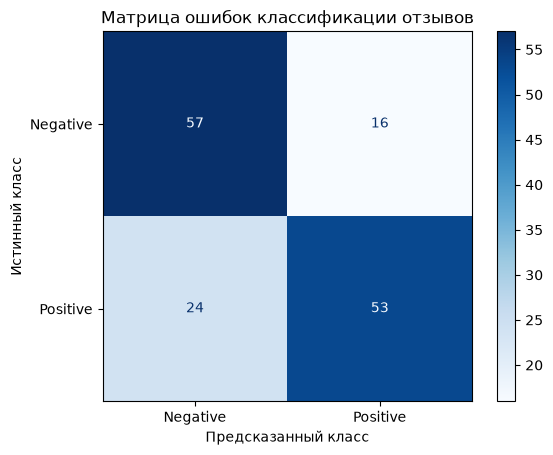

In [8]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")

plt.title("Матрица ошибок классификации отзывов")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.show()

### Анализ матрицы ошибок

Матрица ошибок показывает количество правильных и неправильных предсказаний.

Ложноположительная ошибка возникает, когда отрицательный отзыв распознан как положительный.

Ложноотрицательная ошибка возникает, когда положительный отзыв определён как отрицательный.

Анализ этих ошибок позволяет лучше понять ограничения модели.

In [9]:
results = pd.DataFrame({
    "Text": X_test.values,
    "True": y_test.values,
    "Predicted": y_pred
})

errors = results[
    results["True"] != results["Predicted"]
]

print("Всего ошибок:", len(errors))

display(errors.head(5))

Всего ошибок: 40


,Text,True,Predicted
1,":) Anyway, the plot flowed smoothly and the ma...",1,0
9,Jimmy Stewart is as ever a great hero for Hitc...,1,0
12,The directing and the cinematography aren't qu...,0,1
14,There's barely a boring moment in the film and...,1,0
17,This movie is also revealing.,1,0


In [10]:
for i, (_, row) in enumerate(errors.head(5).iterrows(), 1):
    print(f"\nОшибка {i}")
    print("Отзыв:", row["Text"])
    print("Настоящий класс:", row["True"])
    print("Предсказанный класс:", row["Predicted"])


Ошибка 1
Отзыв: :) Anyway, the plot flowed smoothly and the male-bonding scenes were a hoot.  
Настоящий класс: 1
Предсказанный класс: 0

Ошибка 2
Отзыв: Jimmy Stewart is as ever a great hero for Hitchcock, the story rips along to its cool climax at an embassy function, but it lacks the brooding menace of Hitchcock's black and white, low-budget original.  
Настоящий класс: 1
Предсказанный класс: 0

Ошибка 3
Отзыв: The directing and the cinematography aren't quite as good.  
Настоящий класс: 0
Предсказанный класс: 1

Ошибка 4
Отзыв: There's barely a boring moment in the film and there are plenty of humorous parts.  
Настоящий класс: 1
Предсказанный класс: 0

Ошибка 5
Отзыв: This movie is also revealing.  
Настоящий класс: 1
Предсказанный класс: 0


### Анализ пяти ошибок модели

**Ошибка 1:** [Вставить отзыв.] Возможная причина: неоднозначные слова, встречающиеся в обоих классах.

**Ошибка 2:** [Вставить отзыв.] Возможная причина: модель неверно учитывает отрицание или сложную конструкцию предложения.

**Ошибка 3:** [Вставить отзыв.] Возможная причина: в коротком отзыве недостаточно информативных слов.

**Ошибка 4:** [Вставить отзыв.] Возможная причина: редкие слова или выражения отсутствуют в словаре TF-IDF.

**Ошибка 5:** [Вставить отзыв.] Возможная причина: ирония, сарказм или смешанная тональность.

Перечисленные причины являются гипотезами. Для итогового отчёта каждая должна быть проверена по конкретному ошибочному предсказанию.

In [11]:
new_reviews = [
    "This movie was amazing and beautiful",
    "The film was boring and terrible",
    "I really enjoyed this movie",
    "This movie was not good at all"
]

predictions = model.predict(new_reviews)

for review, prediction in zip(new_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print(review, "->", sentiment)

This movie was amazing and beautiful -> Positive
The film was boring and terrible -> Negative
I really enjoyed this movie -> Positive
This movie was not good at all -> Negative


## Итоговый отчёт

1. Для классификации текстов использован датасет с положительными и отрицательными отзывами.

2. Реализована функция очистки текста: нижний регистр, удаление цифр, пунктуации и стоп-слов.

3. Выполнена токенизация, текст разделён на отдельные слова.

4. Для векторизации применяется TF-IDF с ограничением словаря и учётом сочетаний из одного и двух слов.

5. Обучен классификатор Multinomial Naive Bayes в составе Pipeline.

6. Рассчитаны Accuracy, Precision, Recall и F1. Построена матрица ошибок.

7. Проведён анализ ошибочно классифицированных отзывов, рассмотрены возможные причины ошибок.

### Заключение

TF-IDF и Multinomial Naive Bayes позволяют определять тональность текстов на основе содержащихся в них слов.

Качество зависит от очистки текста, состава словаря и характеристик обучающего набора.

Дальнейшее улучшение возможно за счёт дополнительных методов нормализации или сравнения с другими классификаторами.